# 4. Latent Dirichlet Allocation

Este notebook carga los atributos y la matriz bag of words creados en `3.wordcloud_bow_topic_modeling.ipynb` y entrena un modelo Latent Dirichlet Allocation (LDA) para exploración temática.

Salidas principales:

- palabras principales por tópico;
- distribución tópico-documento con atributos editoriales;
- tópico dominante por documento;
- resumen de tópicos por categoría y por año.


## 1. Configuración


In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.decomposition import LatentDirichletAllocation

warnings.filterwarnings("ignore", category=UserWarning)

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Rutas estándar del proyecto
INPUT_DIR = PROJECT_ROOT / "data" / "processed" / "topic_modeling_lematizado"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "lda"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MATRIX_PATH = INPUT_DIR / "bow_document_term_matrix.npz"
VOCAB_PATH = INPUT_DIR / "bow_vocabulary.csv"
ATTRIBUTES_PATH = INPUT_DIR / "bow_document_attributes.csv"
CONFIG_PATH = INPUT_DIR / "bow_vectorizer_config.json"

assert MATRIX_PATH.exists(), f"Falta matriz BoW en {MATRIX_PATH}. Correr primero Notebook 3."

N_TOPICS = 12
MAX_ITER = 25
LEARNING_METHOD = "online"
RANDOM_STATE = 42
TOP_N_WORDS = 20

OUTPUT_DIR

WindowsPath('C:/Trabajos/anfibia-unsam/outputs/lda')

## 2. Carga de matriz, vocabulario y atributos


In [2]:
bow_matrix = sparse.load_npz(MATRIX_PATH)
vocabulary = pd.read_csv(VOCAB_PATH).sort_values("term_id").reset_index(drop=True)
attributes = pd.read_csv(ATTRIBUTES_PATH)

with open(CONFIG_PATH, encoding="utf-8") as f:
    bow_config = json.load(f)

terms = vocabulary["term"].to_numpy()

assert bow_matrix.shape[0] == len(attributes), "La cantidad de filas de la matriz no coincide con los atributos."
assert bow_matrix.shape[1] == len(terms), "La cantidad de columnas de la matriz no coincide con el vocabulario."

display({
    "documents": bow_matrix.shape[0],
    "terms": bow_matrix.shape[1],
    "non_zero_entries": bow_matrix.nnz,
    "n_topics": N_TOPICS,
})

display(attributes.head())


{'documents': 3557,
 'terms': 43045,
 'non_zero_entries': 2275094,
 'n_topics': 12}

,doc_id,ID,source_url,title_text,tagline,autor_names,post_date,category,text_type,category_list,word_count_model_text
0,0,15668,https://www.revistaanfibia.com/la-china-invisi...,La China invisible,Feria La Salada,Sebastián Hacher; Ariel Wilkis,2012-05-14 13:43:22,['Política y Economía'],['Crónica'],"[""['Política y Economía']""]",4928
1,1,15706,https://www.revistaanfibia.com/grobocopatel-el...,El rico que se cree Steve Jobs,Gustavo Grobocopatel,Graciela Mochkofsky; Alexandre Roig,2012-05-24 13:36:12,['Política y Economía'],['Crónica'],"[""['Política y Economía']""]",3239
2,2,15743,https://www.revistaanfibia.com/la-vaca-sagrada/,La vaca sagrada,NaN,Josefina Licitra,2012-06-05 14:52:58,['Tecnologías'],[],"[""['Tecnologías']""]",5004
3,3,15695,https://www.revistaanfibia.com/los-arruinados-...,Los arruinados del Paraná,Adictos al juego,Gisele Sousa Dias,2012-06-14 10:16:11,['Culturas'],[],"[""['Culturas']""]",4144
4,4,15687,https://www.revistaanfibia.com/de-chile-tacna-...,De Chile a Tacna: una historia de carniceros y...,NaN,Jorge Turpo Rivas,2012-06-25 14:52:05,['Culturas'],['Crónica'],"[""['Culturas']""]",2051


## 3. Entrenamiento del modelo LDA

`N_TOPICS` controla cuántos tópicos se buscan. Conviene probar varios valores y comparar interpretabilidad, perplejidad aproximada y estabilidad de palabras principales.


In [3]:
lda = LatentDirichletAllocation(
    n_components=N_TOPICS,
    max_iter=MAX_ITER,
    learning_method=LEARNING_METHOD,
    random_state=RANDOM_STATE,
    evaluate_every=5,
    n_jobs=-1,
    verbose=1,
)

doc_topic = lda.fit_transform(bow_matrix)

model_diagnostics = {
    "n_topics": N_TOPICS,
    "max_iter": MAX_ITER,
    "learning_method": LEARNING_METHOD,
    "random_state": RANDOM_STATE,
    "bound": float(lda.bound_),
    "perplexity": float(lda.perplexity(bow_matrix)),
    "n_iter": int(lda.n_iter_),
}

model_diagnostics


iteration: 1 of max_iter: 25
iteration: 2 of max_iter: 25
iteration: 3 of max_iter: 25
iteration: 4 of max_iter: 25
iteration: 5 of max_iter: 25, perplexity: 5716.3972
iteration: 6 of max_iter: 25
iteration: 7 of max_iter: 25
iteration: 8 of max_iter: 25
iteration: 9 of max_iter: 25
iteration: 10 of max_iter: 25, perplexity: 5658.6529
iteration: 11 of max_iter: 25
iteration: 12 of max_iter: 25
iteration: 13 of max_iter: 25
iteration: 14 of max_iter: 25
iteration: 15 of max_iter: 25, perplexity: 5639.1821
iteration: 16 of max_iter: 25
iteration: 17 of max_iter: 25
iteration: 18 of max_iter: 25
iteration: 19 of max_iter: 25
iteration: 20 of max_iter: 25, perplexity: 5629.1605
iteration: 21 of max_iter: 25
iteration: 22 of max_iter: 25
iteration: 23 of max_iter: 25
iteration: 24 of max_iter: 25
iteration: 25 of max_iter: 25, perplexity: 5622.9110


{'n_topics': 12,
 'max_iter': 25,
 'learning_method': 'online',
 'random_state': 42,
 'bound': 5622.9109863339,
 'perplexity': 5622.9109863339,
 'n_iter': 25}

## 4. Palabras principales por tópico


In [4]:
def top_words_by_topic(model, terms, top_n=20):
    rows = []
    for topic_idx, topic_weights in enumerate(model.components_):
        top_term_ids = topic_weights.argsort()[::-1][:top_n]
        total_weight = topic_weights.sum()
        for rank, term_id in enumerate(top_term_ids, start=1):
            weight = topic_weights[term_id]
            rows.append({
                "topic": topic_idx,
                "rank": rank,
                "term_id": int(term_id),
                "term": terms[term_id],
                "weight": float(weight),
                "weight_share_in_topic": float(weight / total_weight),
            })
    return pd.DataFrame(rows)

topic_words = top_words_by_topic(lda, terms, top_n=TOP_N_WORDS)
topic_words.to_csv(OUTPUT_DIR / "lda_topic_words.csv", index=False)

display(topic_words.head(TOP_N_WORDS * min(3, N_TOPICS)))


,topic,rank,term_id,term,weight,weight_share_in_topic
0,0,1,37775,social,10726.832174,0.009098
1,0,2,31710,politico,8337.663983,0.007072
2,0,3,31705,politica,7067.836440,0.005995
3,0,4,33157,publico,5862.972557,0.004973
4,0,5,37524,sino,4903.435189,0.004159
5,0,6,37791,sociedad,4195.515286,0.003559
6,0,7,11035,deber,4152.444352,0.003522
7,0,8,11602,derecho,3786.282594,0.003212
8,0,9,29589,pais,3488.213575,0.002959
9,0,10,15701,espacio,3018.385240,0.002560


In [5]:
for topic_idx in range(N_TOPICS):
    words = topic_words.loc[topic_words["topic"].eq(topic_idx), "term"].head(12).tolist()
    print(f"Topic {topic_idx:02d}: " + ", ".join(words))


Topic 00: social, politico, politica, publico, sino, sociedad, deber, derecho, pais, espacio, menos, relacion
Topic 01: futbol, jugar, partido, equipo, mundial, club, jugador, ganar, messi, brasil, cancion, red
Topic 02: libro, escribir, mundo, obra, arte, leer, pelicula, personaje, artista, novela, literatura, escritor
Topic 03: mujer, cuerpo, salud, medico, aborto, madre, casa, agua, sexual, varon, hospital, hijo
Topic 04: periodista, periodismo, diario, noticia, com, periodistico, www, clarin, informacion, redaccion, twitter, http
Topic 05: australia, coetzee, jurado, australiano, holandes, premio, nobel, slow, sudafrica, peronia, july, pampas
Topic 06: pais, empresa, millon, economico, gobierno, estados, mercado, economia, unidos, dolares, sector, trabajo
Topic 07: comunidad, chile, pueblo, indigena, tierra, territorio, bolivia, chileno, morales, boliviano, indigen, constitucion
Topic 08: astrologia, laiseca, gante, marcho, agostina, astral, pci, astrologico, soria, terraplanista, 

## 5. Distribución tópico-documento y tópico dominante


In [6]:
topic_columns = [f"topic_{i:02d}" for i in range(N_TOPICS)]
doc_topic_df = pd.DataFrame(doc_topic, columns=topic_columns)
doc_topic_df.insert(0, "doc_id", attributes["doc_id"].to_numpy())

dominant_topic = doc_topic.argmax(axis=1)
dominant_topic_weight = doc_topic.max(axis=1)

document_topics = attributes.copy()
document_topics["dominant_topic"] = dominant_topic
document_topics["dominant_topic_weight"] = dominant_topic_weight
document_topics = pd.concat([document_topics, doc_topic_df[topic_columns]], axis=1)

doc_topic_df.to_csv(OUTPUT_DIR / "lda_document_topic_matrix.csv", index=False)
document_topics.to_csv(OUTPUT_DIR / "lda_document_topics_with_attributes.csv", index=False)

display(document_topics[["doc_id", "title_text", "category", "post_date", "dominant_topic", "dominant_topic_weight"]].head(10))


,doc_id,title_text,category,post_date,dominant_topic,dominant_topic_weight
0,0,La China invisible,['Política y Economía'],2012-05-14 13:43:22,9,0.858515
1,1,El rico que se cree Steve Jobs,['Política y Economía'],2012-05-24 13:36:12,9,0.495098
2,2,La vaca sagrada,['Tecnologías'],2012-06-05 14:52:58,3,0.667504
3,3,Los arruinados del Paraná,['Culturas'],2012-06-14 10:16:11,9,0.653649
4,4,De Chile a Tacna: una historia de carniceros y...,['Culturas'],2012-06-25 14:52:05,3,0.448667
5,5,Bolivia en llamas,['Política y Economía'],2012-06-28 14:19:51,9,0.478230
6,6,Los líderes de la primavera mexicana (I),['Política y Economía'],2012-07-06 13:27:04,9,0.537787
7,7,Nunca te metas con las mariscadoras de Vigo,['Política y Economía'],2012-07-16 17:08:34,9,0.617449
8,8,"Lucía, la remadora olímpica de las manos impos...",['Culturas'],2012-07-23 17:32:48,9,0.395777
9,9,El fisicoculturista que no puede mirarse en el...,['Culturas'],2012-07-30 15:38:38,9,0.592421


## 6. Documentos más representativos por tópico


In [7]:
representative_docs = []
for topic_idx, column in enumerate(topic_columns):
    top_docs = document_topics.sort_values(column, ascending=False).head(10)
    for rank, (_, row) in enumerate(top_docs.iterrows(), start=1):
        representative_docs.append({
            "topic": topic_idx,
            "rank": rank,
            "doc_id": row["doc_id"],
            "ID": row["ID"],
            "title_text": row["title_text"],
            "category": row["category"],
            "post_date": row["post_date"],
            "topic_weight": row[column],
            "source_url": row["source_url"],
        })

representative_docs = pd.DataFrame(representative_docs)
representative_docs.to_csv(OUTPUT_DIR / "lda_representative_documents.csv", index=False)

display(representative_docs.head(30))


,topic,rank,doc_id,ID,title_text,category,post_date,topic_weight,source_url
0,0,1,3046,195310,¿Es posible una democracia liberal en la Argen...,['Política y Economía'],2024-04-03 12:53:16,0.998927,https://www.revistaanfibia.com/es-posible-una-...
1,0,2,2176,150080,La autoridad pedagógica en jaque,['Educación'],2020-11-18 12:55:08,0.991996,https://www.revistaanfibia.com/la-autoridad-pe...
2,0,3,2838,186553,Un futuro mejor posible,['Otras'],2023-06-16 10:00:00,0.988076,https://www.revistaanfibia.com/formacion-profe...
3,0,4,999,58259,Más que sensiblería y motivación,['Política y Economía'],2017-02-02 10:37:14,0.985079,https://www.revistaanfibia.com/mas-sensibleria...
4,0,5,584,33163,Los encantos del poder,['Política y Economía'],2015-11-13 14:40:36,0.979412,https://www.revistaanfibia.com/los-encantos-de...
5,0,6,3325,204311,La fórmula latinoamericana,['Política y Economía'],2025-05-28 10:57:34,0.976057,https://www.revistaanfibia.com/la-formula-lati...
6,0,7,2217,151109,"Medios, redes y polarización",['Política y Economía'],2021-01-21 14:59:15,0.972891,https://www.revistaanfibia.com/medios-redes-y-...
7,0,8,2546,171157,Intoxicados: ¿Qué hacer ante los discursos de ...,['Tecnologías'],2022-04-18 09:37:03,0.953358,https://www.revistaanfibia.com/intoxicados-que...
8,0,9,2527,169790,Cinco razones para hacer Sociología Política,['Educación'],2022-03-14 15:17:00,0.951631,https://www.revistaanfibia.com/cinco-razones-p...
9,0,10,1735,119553,¿Hacia dónde vamos?,['Políticas de géneros'],2019-03-07 14:56:54,0.950770,https://www.revistaanfibia.com/hacia-donde-vamos/


## 7. Resumen por categoría y año


In [8]:
document_topics["post_date_dt"] = pd.to_datetime(document_topics["post_date"], errors="coerce")
document_topics["post_year"] = document_topics["post_date_dt"].dt.year

category_topic_summary = (
    document_topics
    .groupby("category", dropna=False)[topic_columns]
    .mean()
    .reset_index()
)
category_topic_summary["documents"] = document_topics.groupby("category", dropna=False).size().to_numpy()
category_topic_summary.to_csv(OUTPUT_DIR / "lda_category_topic_summary.csv", index=False)

year_topic_summary = (
    document_topics
    .dropna(subset=["post_year"])
    .groupby("post_year")[topic_columns]
    .mean()
    .reset_index()
)
year_topic_summary["documents"] = document_topics.dropna(subset=["post_year"]).groupby("post_year").size().to_numpy()
year_topic_summary.to_csv(OUTPUT_DIR / "lda_year_topic_summary.csv", index=False)

display(category_topic_summary.sort_values("documents", ascending=False).head(15))
display(year_topic_summary.tail(15))


,category,topic_00,topic_01,topic_02,topic_03,topic_04,topic_05,topic_06,topic_07,topic_08,topic_09,topic_10,topic_11,documents
26,['Política y Economía'],0.369916,0.020350,0.017866,0.028647,0.005490,0.000224,0.122055,0.006699,0.000103,0.189294,0.083323,0.156032,1350
17,['Culturas'],0.210950,0.118618,0.131482,0.053312,0.012276,0.001041,0.027608,0.003031,0.000355,0.386136,0.029692,0.025500,985
28,['Políticas de géneros'],0.354017,0.027607,0.035417,0.171443,0.011156,0.000185,0.017994,0.003343,0.000302,0.226911,0.099031,0.052594,521
22,['Otras'],0.222200,0.075011,0.089959,0.069818,0.112026,0.003345,0.036016,0.005148,0.000464,0.294900,0.044521,0.046593,161
29,['Salud'],0.265483,0.018510,0.036654,0.364219,0.006334,0.000258,0.074196,0.001316,0.000110,0.202629,0.014587,0.015703,117
4,['Ambiente'],0.230556,0.006248,0.036436,0.177969,0.002145,0.000402,0.253627,0.011966,0.000096,0.248428,0.023839,0.008288,100
30,['Tecnologías'],0.441944,0.106035,0.082716,0.053038,0.034638,0.000271,0.152306,0.000771,0.000116,0.114606,0.006933,0.006626,98
20,['Educación'],0.553852,0.011721,0.039919,0.067180,0.003836,0.002191,0.061565,0.000658,0.000429,0.216446,0.013201,0.029001,75
8,['Amor y sexo'],0.241815,0.115891,0.121317,0.197764,0.003406,0.000328,0.012640,0.000626,0.000114,0.289188,0.008369,0.008542,51
12,['Culturas' 'Política y Economía'],0.373614,0.083870,0.093355,0.039802,0.009440,0.000421,0.081078,0.001444,0.000084,0.229782,0.037088,0.050022,33


,post_year,topic_00,topic_01,topic_02,topic_03,topic_04,topic_05,topic_06,topic_07,topic_08,topic_09,topic_10,topic_11,documents
0,2012,0.065645,0.060551,0.041118,0.137327,0.004974,0.000068,0.044115,0.011235,0.000068,0.511066,0.050213,0.073619,29
1,2013,0.089110,0.076534,0.039493,0.107510,0.003131,0.000169,0.024504,0.010573,0.000081,0.526923,0.083001,0.038971,47
2,2014,0.213925,0.088017,0.086028,0.065530,0.022258,0.002498,0.038027,0.002683,0.000158,0.393644,0.052961,0.034271,234
3,2015,0.245469,0.030012,0.073976,0.062918,0.011013,0.002015,0.038210,0.004463,0.000153,0.382268,0.055651,0.093851,317
4,2016,0.262678,0.041451,0.067015,0.069967,0.013259,0.001020,0.073353,0.002544,0.000340,0.319222,0.069642,0.079510,351
5,2017,0.329270,0.066649,0.058635,0.063202,0.049580,0.000428,0.044476,0.004537,0.000328,0.215258,0.085964,0.081673,349
6,2018,0.350663,0.075224,0.049186,0.111412,0.013127,0.000401,0.065495,0.002461,0.000316,0.202782,0.053954,0.074980,369
7,2019,0.349571,0.048221,0.044969,0.076203,0.017098,0.000292,0.090286,0.006355,0.000393,0.208614,0.045080,0.112918,255
8,2020,0.350510,0.036512,0.038336,0.147359,0.006021,0.000287,0.126993,0.005903,0.000119,0.206303,0.044317,0.037339,257
9,2021,0.388609,0.049011,0.065001,0.089374,0.007286,0.000164,0.087383,0.006952,0.000292,0.180603,0.046441,0.078884,278


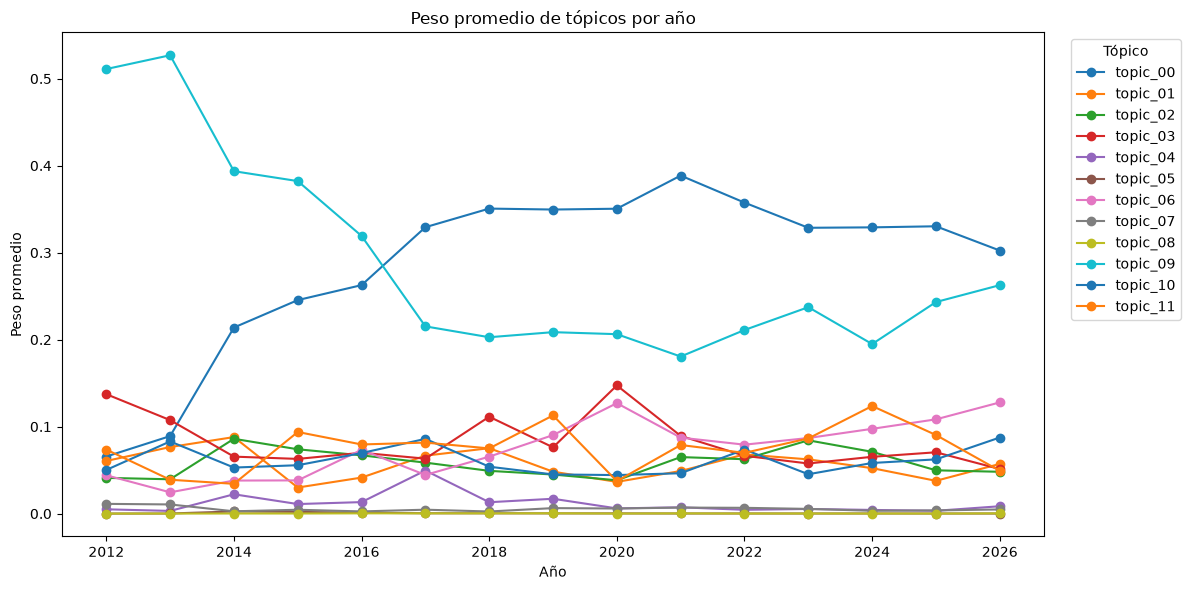

In [9]:
plot_topics = topic_columns[: min(N_TOPICS, len(topic_columns))]
ax = year_topic_summary.set_index("post_year")[plot_topics].plot(figsize=(12, 6), marker="o")
ax.set_title("Peso promedio de tópicos por año")
ax.set_xlabel("Año")
ax.set_ylabel("Peso promedio")
ax.legend(title="Tópico", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 8. Guardado del modelo y configuración

El modelo se guarda con `joblib` para poder reutilizarlo sin reentrenar.


In [10]:
try:
    import joblib

    joblib.dump(lda, OUTPUT_DIR / "lda_model.joblib")
    model_file = "lda_model.joblib"
except ModuleNotFoundError:
    model_file = None

with open(OUTPUT_DIR / "lda_model_config.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            **model_diagnostics,
            "top_n_words": TOP_N_WORDS,
            "input_matrix": str(MATRIX_PATH.relative_to(PROJECT_ROOT)),
            "input_vocabulary": str(VOCAB_PATH.relative_to(PROJECT_ROOT)),
            "input_attributes": str(ATTRIBUTES_PATH.relative_to(PROJECT_ROOT)),
            "model_file": model_file,
            "outputs": {
                "topic_words": "lda_topic_words.csv",
                "document_topic_matrix": "lda_document_topic_matrix.csv",
                "document_topics_with_attributes": "lda_document_topics_with_attributes.csv",
                "representative_documents": "lda_representative_documents.csv",
                "category_topic_summary": "lda_category_topic_summary.csv",
                "year_topic_summary": "lda_year_topic_summary.csv",
            },
        },
        f,
        ensure_ascii=False,
        indent=2,
    )

sorted(path.name for path in OUTPUT_DIR.glob("lda_*"))


['lda_category_topic_summary.csv',
 'lda_document_topic_matrix.csv',
 'lda_document_topics_with_attributes.csv',
 'lda_model.joblib',
 'lda_model_config.json',
 'lda_representative_documents.csv',
 'lda_topic_words.csv',
 'lda_year_topic_summary.csv']

## 9. Próximos ajustes posibles

Para comparar modelos, cambiar `N_TOPICS` y volver a ejecutar. Una práctica simple es guardar cada corrida en una carpeta distinta, por ejemplo `output/lda/k_08`, `output/lda/k_12`, `output/lda/k_16`, y comparar interpretabilidad de palabras/documentos representativos.
